# 03 · Monthly Monitoring, Dashboard, API and Deployment Preparation

## 1. Configuration

In [5]:
# !pip install -r ../requirements.txt      # <- uncomment to install dependencies from inside Jupyter

import sys, json, subprocess, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=PendingDeprecationWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUTPUT_DIR = ROOT / "outputs"
CLEAN_FILE = OUTPUT_DIR / "cleaned_jobs.csv.gz"
MONTHLY_DIR = OUTPUT_DIR / "monthly"
DASH_DIR = OUTPUT_DIR / "dashboard"
TABLE_DIR, MODEL_DIR, REC_DIR = OUTPUT_DIR / "tables", OUTPUT_DIR / "model", OUTPUT_DIR / "recommendations"
sys.path.insert(0, str(ROOT / "app"))
import preprocessing as pp
import reporting as rp

MIN_COMPLETE_DAYS = 7     # a month needs at least this many complete days to be reported at all
TOP_N = 10                # rows shown in comparison tables
API_PORT = 5055           # port used for the live API test below
sns.set_theme(style="whitegrid", context="notebook")
pd.options.display.float_format = "{:,.2f}".format

if not CLEAN_FILE.exists():
    raise FileNotFoundError(f"{CLEAN_FILE} not found. Run notebook 01_Job_Market_EDA.ipynb first.")
jobs = rp.load_clean(CLEAN_FILE)
print(f"Loaded {len(jobs):,} cleaned postings ({jobs['published_at'].min():%Y-%m-%d} -> {jobs['published_at'].max():%Y-%m-%d}).")

Loaded 244,291 cleaned postings (2023-11-02 -> 2024-03-24).



# Part A -Track job-market dynamics month by month

## A1. Which months can we trust?

In [6]:
report = rp.build_monthly_report(jobs, min_complete_days=MIN_COMPLETE_DAYS, top_n=TOP_N)
display(report["coverage"])
meta = report["comparison_meta"].iloc[0]
print(f"Latest month: {meta['latest_month']} | previous month: {meta['previous_month']}")
n_partial = (report["coverage"]["status"] == "partial").sum()
print(f"-> {n_partial} partial month(s) in the reportable set; all comparisons below are marked PROVISIONAL.")

,month,calendar_days,days_with_any_data,complete_days,coverage_pct,total_postings_all_days,status
0,2023-11,30,1,0,0.00,1,sparse
1,2023-12,31,10,0,0.00,10,sparse
2,2024-01,31,25,0,0.00,96,sparse
3,2024-02,29,29,12,41.40,101686,partial
4,2024-03,31,24,23,74.20,142498,partial


Latest month: 2024-03 | previous month: 2024-02
-> 2 partial month(s) in the reportable set; all comparisons below are marked PROVISIONAL.


## A2. Monthly indicators and latest-vs-previous changes
**Total postings**

In [7]:
display(report["volume"][["month", "status", "complete_days", "total_postings_all_days", "postings_complete_days", "postings_per_day", "postings_per_day_weekday_balanced"]])
print("Latest vs previous month (absolute and % change in postings per complete day):")
display(report["comparison_volume"])

,month,status,complete_days,total_postings_all_days,postings_complete_days,postings_per_day,postings_per_day_weekday_balanced
0,2024-02,partial,12,101686,79845,"6,653.75","6,388.57"
1,2024-03,partial,23,142498,140318,"6,100.78","6,156.63"


Latest vs previous month (absolute and % change in postings per complete day):


,metric,2024-02,2024-03,abs_change,pct_change,provisional
0,postings_per_day,"6,653.75","6,100.78",-552.97,-8.31,True
1,postings_per_day_weekday_balanced,"6,388.57","6,156.63",-231.94,-3.63,True


**Job categories and titles**

In [8]:
display(report["comparison_categories"].round(1))
latest_titles = (jobs[(jobs["month"] == meta["latest_month"]) & jobs["is_complete_day"]]["title_norm"].value_counts().head(10)
                 .to_frame("postings"))
print(f"Most frequent exact titles in {meta['latest_month']} (complete days):")
display(latest_titles)

month,category,per_day_2024-02,per_day_2024-03,abs_change,pct_change,provisional
0,Web Development & CMS,872.10,817.90,-54.20,-6.20,True
1,Other / Unclassified,743.30,676.60,-66.70,-9.00,True
2,Video & Animation,630.80,621.10,-9.70,-1.50,True
3,Graphic Design & Branding,629.50,583.60,-45.90,-7.30,True
4,"Marketing, SEO & Social Media",570.70,544.40,-26.30,-4.60,True
5,Software Development,369.00,342.00,-27.00,-7.30,True
6,E-commerce & Marketplaces,319.20,297.50,-21.60,-6.80,True
7,Mobile App Development,290.80,269.30,-21.60,-7.40,True
8,Writing & Content,351.40,238.00,-113.40,-32.30,True
9,Sales & Lead Generation,233.80,216.70,-17.20,-7.30,True


Most frequent exact titles in 2024-03 (complete days):


,postings
title_norm,
logo design,303
social media manager,291
video editor,261
graphic designer,221
virtual assistant,194
youtube video editor,116
lead generation,107
logo designer,99
full stack developer,97


**Salary indicators** (medians, hourly and fixed-price kept separate), **remote-work signal** (title wording only — see Notebook 1, Task 7) and **country-level demand**

In [9]:
display(report["comparison_salary"])
display(report["comparison_remote"])
display(report["comparison_countries"].round(1))

,metric,2024-02,2024-03,abs_change,pct_change,provisional
0,median_hourly_mid_usd,22.50,22.50,0.00,0.00,True
1,median_fixed_budget_usd,100.00,100.00,0.00,0.00,True
2,hourly_share_pct,58.33,57.03,-1.29,-2.22,True
3,hourly_rate_disclosed_pct,71.19,69.47,-1.72,-2.42,True


,metric,2024-02,2024-03,abs_change,pct_change,provisional
0,remote_mentioned_pct,0.55,0.56,0.01,1.62,True


month,country,per_day_2024-02,per_day_2024-03,abs_change,pct_change,provisional
0,United States,"2,708.50","2,487.50",-221.00,-8.20,True
1,United Kingdom,509.10,483.70,-25.40,-5.00,True
2,India,441.90,390.70,-51.20,-11.60,True
3,Australia,351.90,313.00,-38.90,-11.10,True
4,Canada,309.20,295.30,-13.90,-4.50,True
5,Pakistan,144.40,122.00,-22.50,-15.60,True
6,Germany,131.20,119.20,-11.90,-9.10,True
7,Netherlands,125.20,110.30,-14.90,-11.90,True
8,United Arab Emirates,103.80,102.00,-1.80,-1.80,True
9,France,87.10,77.00,-10.00,-11.50,True


**Emerging roles.** Title keywords whose postings-per-day grew most between the two months (≥ 100 postings in the latest month). With only two partial months these are *candidate signals*,
not confirmed trends.

In [10]:
display(report["emerging_keywords"].round(1))

,keyword,per_day_2024-02,per_day_2024-03,abs_change_per_day,pct_change,provisional
0,meme,1.70,4.50,2.80,168.70,True
1,mark,2.30,5.20,2.90,123.60,True
2,solana,3.60,7.50,3.90,109.90,True
3,subscription,4.30,8.70,4.40,101.70,True
4,france,2.30,4.60,2.20,95.70,True
5,token,3.10,5.20,2.10,69.20,True
6,water,4.90,8.30,3.30,68.00,True
7,pixel,5.20,8.70,3.40,64.80,True
8,enhance,3.40,5.50,2.10,61.60,True
9,grow,5.20,8.20,2.90,55.70,True


## A3. Week-level view (more granular, complete weeks only)
Because no month is complete, a weekly view gives a fairer picture of change.

,postings,hourly_median,fixed_median,wow_%
week_start,,,,
2024-02-19,45449,22.50,100.00,NaN
2024-02-26,43546,22.50,100.00,-4.19
2024-03-04,43615,22.50,100.00,0.16
2024-03-11,42915,22.50,100.00,-1.60


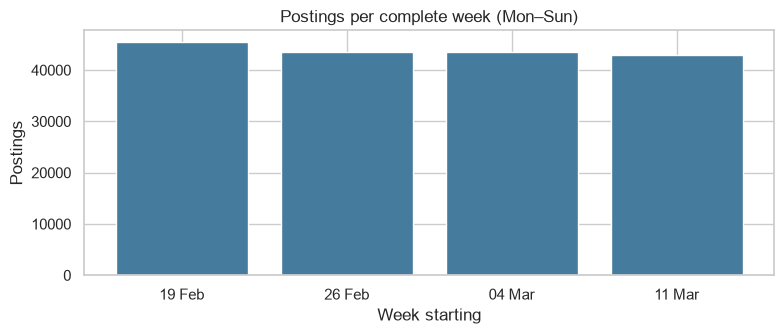

In [11]:
core = jobs[jobs["in_core_window"]]
full_weeks = core.groupby("week_start")["date"].nunique().loc[lambda s: s == 7].index
wk = core[core["week_start"].isin(full_weeks)].groupby("week_start").agg(postings=("link", "size"), hourly_median=("hourly_mid_usd", "median"),
                                                                      fixed_median=("fixed_budget_usd", "median"))
wk["wow_%"] = wk["postings"].pct_change() * 100
display(wk)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(wk.index.strftime("%d %b"), wk["postings"], color="#457b9d")
ax.set_title("Postings per complete week (Mon–Sun)"); ax.set_xlabel("Week starting"); ax.set_ylabel("Postings")
plt.tight_layout(); plt.show()

## A4. Save the monthly report and inventory the outputs
Cleaned data, aggregated summaries, model outputs and recommendation results go into separate folders under `outputs/`.

In [12]:
saved = rp.save_report(report, MONTHLY_DIR)
print(f"Saved {len(saved)} monthly tables to {MONTHLY_DIR.relative_to(ROOT)}/")
inventory = []
for folder, what in ((OUTPUT_DIR, "cleaned data"), (TABLE_DIR, "Task 1/2/4/7 tables (Notebook 1)"), (MODEL_DIR, "forecasts & model comparison (Notebook 2)"),
                     (REC_DIR, "recommendation samples & evaluation (Notebook 2)"), (MONTHLY_DIR, "monthly report (this notebook)")):
    files = sorted(p.name for p in folder.glob("*") if p.is_file()) if folder.exists() else []
    inventory.append({"folder": str(folder.relative_to(ROOT)), "contents": what, "n_files": len(files), "files": ", ".join(files[:6]) + (" ..." if len(files) > 6 else "")})
display(pd.DataFrame(inventory))

Saved 13 monthly tables to outputs\monthly/


,folder,contents,n_files,files
0,outputs,cleaned data,2,"README_outputs.md, cleaned_jobs.csv.gz"
1,outputs\tables,Task 1/2/4/7 tables (Notebook 1),5,"task1_keyword_salary_effects.csv, task2_catego..."
2,outputs\model,forecasts & model comparison (Notebook 2),6,"forecast_categories_14d.csv, forecast_categori..."
3,outputs\recommendations,recommendation samples & evaluation (Notebook 2),2,"recommender_proxy_evaluation.csv, sample_recom..."
4,outputs\monthly,monthly report (this notebook),13,"monthly_categories.csv, monthly_comparison_cat..."


## A5. How the monthly update would work

In [13]:
overlap = jobs.sample(5000, random_state=42)
merged = rp.append_new_data(jobs, overlap)
print(f"Idempotent append: {len(jobs):,} existing + {len(overlap):,} overlapping rows -> {len(merged):,} rows "
      f"({'OK, no duplicates' if len(merged) == len(jobs) else 'PROBLEM'})")
assert len(merged) == len(jobs)

for label, bad in (("empty table", jobs.iloc[0:0]), ("only sparse days (3 postings)", jobs.sort_values("published_at").head(3))):
    try:
        rp.build_monthly_report(bad)
    except ValueError as exc:
        print(f"{label:30s}-> ValueError: {exc}")
try:
    pp.validate_schema(jobs[["title_clean", "category"]])      # a table without the raw columns the pipeline needs
except KeyError as exc:
    print(f"{'missing columns':30s}-> KeyError: {exc}")

Idempotent append: 244,291 existing + 5,000 overlapping rows -> 244,291 rows (OK, no duplicates)
empty table                   -> ValueError: Cannot build a report from an empty table.
only sparse days (3 postings) -> ValueError: No month has >= 7 complete days; report not possible.
missing columns               -> KeyError: "Missing required column(s): ['title', 'link', 'published_date', 'is_hourly', 'hourly_low', 'hourly_high', 'budget', 'country']. Found: ['title_clean', 'category']"


## A6. Interactive Plotly dashboard (prototype)
`app/dashboard.py` returns Plotly figures from the report tables; the same functions can be reused in Streamlit/Dash. Here we assemble them into one standalone HTML page
(`outputs/dashboard/dashboard_prototype.html`) and also show them inline. **Requires `plotly`** (`pip install plotly`).

In [14]:
import sys
from pathlib import Path

APP_DIR = Path(r"D:\PERSONAL\Project 8\app")
sys.path.insert(0, str(APP_DIR))

import dashboard as dash_mod

In [15]:
from pathlib import Path

ROOT = Path(r"D:\PERSONAL\Project 8")
TABLE_DIR = ROOT / "outputs" / "tables"

print("Tables folder:", TABLE_DIR)
print("Folder exists:", TABLE_DIR.exists())

Tables folder: D:\PERSONAL\Project 8\outputs\tables
Folder exists: True


In [16]:
try:
    import plotly.express as px
    import plotly.graph_objects as go
except ImportError as exc:
    raise ImportError("Plotly is required for the dashboard: pip install plotly") from exc
import dashboard as dash_mod

country_hourly = None
f = TABLE_DIR / "task4_hourly_rate_by_country.csv"
if f.exists():
    country_hourly = pd.read_csv(f)
else:
    print("(skipping hourly-rate map: run Notebook 1 to create", f.name, ")")
history = forecast = None
if (MODEL_DIR / "forecast_total_daily.csv").exists():
    forecast = pd.read_csv(MODEL_DIR / "forecast_total_daily.csv", index_col=0, parse_dates=True)
    daily = core.groupby("date").size()
    history = daily
else:
    print("(skipping forecast panel: run Notebook 2 to create forecast_total_daily.csv)")

figs = dash_mod.build_figures(report, country_hourly=country_hourly, history=history, forecast=forecast)
note = ("Prototype built from a static Feb–Mar 2024 snapshot. Months are PARTIAL, so comparisons are provisional. "
        "Categories are derived from title keywords. No live data feed.")
html_path = dash_mod.figures_to_html(figs, DASH_DIR / "dashboard_prototype.html", note=note)
print("Saved:", html_path.relative_to(ROOT), "| panels:", list(figs))
for name, fig in figs.items():
    fig.show()

Saved: outputs\dashboard\dashboard_prototype.html | panels: ['volume', 'category_share', 'category_change', 'country_change', 'hourly_map', 'forecast']


---
# Part B -Recommendation REST API (Flask)


## B1. Run it locally
```bash
pip install -r requirements.txt          # from the project root
cd app && python app.py                  # http://127.0.0.1:5000   (first request builds the index, ~10 s)
curl http://127.0.0.1:5000/health
curl -X POST http://127.0.0.1:5000/recommend -H "Content-Type: application/json" \
     -d '{"role": "wordpress developer", "skills": ["woocommerce"], "min_hourly_rate": 20, "top_k": 3}'
```
## B2. Test the real server from this notebook
The next cell starts the server as a subprocess on a free local port, calls it over HTTP with `requests`, and always shuts it down afterwards.

In [17]:
import requests, os

env = {**os.environ, "JOBS_DATA_PATH": str(CLEAN_FILE), "PORT": str(API_PORT), "PRELOAD": "1"}
proc = subprocess.Popen([sys.executable, "app.py"], cwd=ROOT / "app", env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
base = f"http://127.0.0.1:{API_PORT}"
try:
    for _ in range(90):                                   # wait up to ~90 s for the index to be built
        try:
            if requests.get(base + "/health", timeout=2).ok:
                break
        except requests.ConnectionError:
            time.sleep(1)
    else:
        raise RuntimeError("API did not start in time:\n" + (proc.stdout.read() if proc.poll() is not None else "still starting"))

    print("GET /health ->", requests.get(base + "/health").json())
    meta_resp = requests.get(base + "/meta").json()
    print("GET /meta   ->", {k: (v if k != "countries" else f"{len(v)} countries") for k, v in meta_resp.items()})

    example_request = {"role": "wordpress developer", "skills": ["woocommerce", "elementor"], "country": "United States",
                       "employment_type": "hourly", "min_hourly_rate": 20, "top_k": 3}
    r = requests.post(base + "/recommend", json=example_request)
    print("\nPOST /recommend  request:", json.dumps(example_request))
    print("status:", r.status_code)
    example_response = r.json()
    shown = {**example_response, "recommendations": example_response["recommendations"][:1]}
    print("response (first recommendation only):")
    print(json.dumps(shown, indent=2)[:3500])

    print("\n--- error handling ---")
    r = requests.post(base + "/recommend", json={"role": "logo", "top_k": 500, "employment_type": "contract"})
    print(r.status_code, r.json())
    r = requests.post(base + "/recommend", data="not json", headers={"Content-Type": "application/json"})
    print(r.status_code, r.json())
    r = requests.post(base + "/recommend", data="role=logo")
    print(r.status_code, r.json())
    r = requests.get(base + "/does-not-exist")
    print(r.status_code, r.json())
finally:
    proc.terminate()
    try:
        proc.wait(timeout=10)
    except subprocess.TimeoutExpired:
        proc.kill()
    print("\nServer stopped.")

GET /health -> {'status': 'ok', 'model_loaded': True}
GET /meta   -> {'n_postings': 244291, 'newest_posting': '2024-03-24 14:16:47+00:00', 'employment_types': ['any', 'fixed_price', 'hourly'], 'work_modes': ['any', 'hybrid', 'onsite', 'remote'], 'experience_levels': ['any', 'junior', 'mid', 'senior'], 'countries': '212 countries', 'notes': ['No company, experience-level or work-mode fields exist in the source data.', 'Pay is in USD as shown on the platform (assumption).']}

POST /recommend  request: {"role": "wordpress developer", "skills": ["woocommerce", "elementor"], "country": "United States", "employment_type": "hourly", "min_hourly_rate": 20, "top_k": 3}
status: 200
response (first recommendation only):
{
  "preferences": {
    "role": "wordpress developer",
    "skills": [
      "woocommerce",
      "elementor"
    ],
    "country": [
      "United States"
    ],
    "strict_country": true,
    "employment_type": "hourly",
    "work_mode": "any",
    "experience_level": "any",
 

**Response structure.** `recommendations[i]` contains `rank`, `score`, `score_breakdown` (per component), `job_title`, `company` (**always `null`**: not in the data), `location` (client country),
`employment_type`, `pay`, `hourly_low/high`, `fixed_budget`, `work_mode` (explains that the data has none), `category`, `matched_keywords`, `relevant_skills`, `published_at`, `url` (the original Upwork link)
and `why_recommended` (human-readable reasons). Top-level fields: `n_candidates`, `warnings`, `weights_used`, `reference_date`, `preferences` (the validated input).

## B3. Unit-style checks of the API without a network (Flask test client)
Fast, deterministic checks that can be reused in CI.

In [18]:
import app as job_api
from recommender import JobRecommender

small = JobRecommender(jobs.sample(20000, random_state=42))          # a small index keeps the test quick
client = job_api.create_app(recommender=small).test_client()
checks = {
    "health ok": client.get("/health").status_code == 200,
    "valid request -> 200": client.post("/recommend", json={"role": "logo design", "top_k": 3}).status_code == 200,
    "empty body -> 400": client.post("/recommend", json={}).status_code == 400,
    "bad type -> 400": client.post("/recommend", json={"role": ["x"]}).status_code == 400,
    "non-JSON -> 415": client.post("/recommend", data="x").status_code == 415,
    "wrong method -> 405": client.get("/recommend").status_code == 405,
    "top_k respected": len(client.post("/recommend", json={"role": "video editor", "top_k": 2}).json["recommendations"]) <= 2,
    "company never invented": all(x["company"] is None for x in client.post("/recommend", json={"role": "video editor"}).json["recommendations"]),
    "urls come from data": all(x["url"] in set(small.jobs["link"]) for x in client.post("/recommend", json={"role": "video editor"}).json["recommendations"]),
}
display(pd.Series(checks, name="passed").to_frame())
assert all(checks.values()), "an API check failed"

,passed
health ok,True
valid request -> 200,True
empty body -> 400,True
bad type -> 400,True
non-JSON -> 415,True
wrong method -> 405,True
top_k respected,True
company never invented,True
urls come from data,True
